# M02-2 | 不用 Quantizer，自己把 observer 與 fake quant 插進圖裡

M01 看到 `prepare_pt2e` 在圖上插 observer。位置由 Quantizer 決定（M03 的主題）；把「決定位置」拿掉，剩下的就是改圖：

1. 建一個 observer 模組，用 `gm.add_submodule(name, module)` 掛到 GraphModule 上。
2. 在圖上插一個 `call_module` node，讓原本吃上游的 consumer 改吃它。

這兩步就是 M00-4 的 Step 1～3（插入、改接、recompile）。不熟的話先跑一次 [M00-4](../m00_export_basics/04_fx_graph_editing.ipynb)。

- **A.** 在 conv → relu 的三個位置手插 observer，校準後與 `prepare_pt2e` 的 qparams 逐項比對。
- **B.** 把 observer 換成 `FakeQuantize`：位置相同，但 forward 會真的 quantize → dequantize。
- **C.** `FakeQuantize` 的兩個開關：`observer_enabled`、`fake_quant_enabled`。

模型是沒有 BN 的 `ConvReLU`，避免 `prepare_pt2e` 折 BN 讓圖不一樣（M04）。

In [1]:
import copy

import torch

from common.graph_utils import observer_nodes, sqnr
from common.models import example_inputs, get_model
from common.pt2e import (
    FakeQuantize,
    MinMaxObserver,
    PerChannelMinMaxObserver,
    disable_fake_quant,
    disable_observer,
    enable_fake_quant,
    enable_observer,
    export_module,
    get_xnnpack_quantizer,
    prepare_pt2e,
    quiet,
)
from common.viz import draw, draw_stages, table

quiet()
_ = torch.manual_seed(0)

## A. 手插 observer，和 `prepare_pt2e` 比對

插入的核心動作只有三行：掛模組、在 `node` 之後建 `call_module`、把 `node` 的使用者改接到新 node（新 node 自己除外）。

In [2]:
def insert_after(gm, node, module, name):
    """在 node 之後插入 call_module(name)，原本吃 node 的使用者改吃新 node。"""
    gm.add_submodule(name, module)                       # 1. 掛模組，call_module 才找得到
    with gm.graph.inserting_after(node):
        new = gm.graph.call_module(name, (node,))        # 2a. 新 node：name(node)
    node.replace_all_uses_with(new, delete_user_cb=lambda user: user is not new)  # 2b. 改接下游
    return new

要插在哪、插哪種 observer？為了能和 `prepare_pt2e` 逐項比對，兩者都照 XNNPACKQuantizer 的設定：

- **位置**：輸入 `x`、conv 的 weight、relu 的輸出（M01 概覽的例子裡，`prepare_pt2e` 也是插在這三處）。
- **observer 的種類與參數**：直接從 quantizer 設定裡的 `QuantizationSpec` 建，不在這裡寫死。這也是 `prepare_pt2e` 對每個標籤做的事。

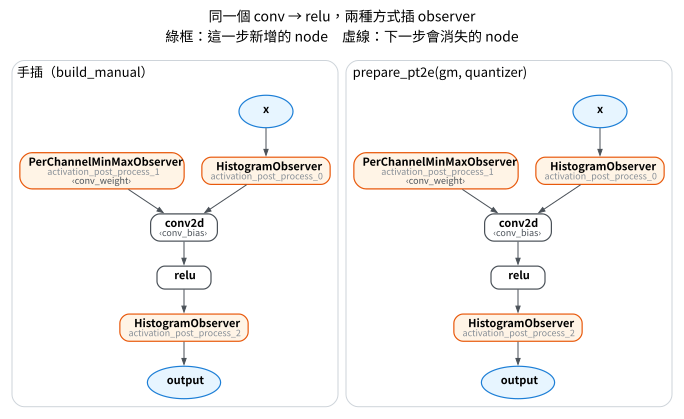

In [3]:
def observer_from_spec(spec):
    """依 QuantizationSpec 建出 observer。"""
    kwargs = dict(dtype=spec.dtype, qscheme=spec.qscheme, quant_min=spec.quant_min,
                  quant_max=spec.quant_max, is_dynamic=spec.is_dynamic)
    if spec.ch_axis is not None:
        kwargs["ch_axis"] = spec.ch_axis
    return spec.observer_or_fake_quant_ctr.with_args(**kwargs)()


def build_manual(gm, make_act, make_weight):
    """在 x、conv weight、relu 輸出三個位置插入，名稱照 prepare_pt2e 的慣例。"""
    by_name = {n.name: n for n in gm.graph.nodes}
    insert_after(gm, by_name["x"], make_act(), "activation_post_process_0")
    insert_after(gm, by_name["conv_weight"], make_weight(), "activation_post_process_1")
    insert_after(gm, by_name["relu"], make_act(), "activation_post_process_2")
    gm.recompile()  # 改完圖一定要 recompile，forward 才會更新
    return gm


model = get_model("conv_relu").eval()
gm = export_module(model, example_inputs(4))
quantizer, _ = get_xnnpack_quantizer(is_per_channel=True)
cfg = quantizer.global_config
assert cfg is not None and cfg.input_activation is not None and cfg.weight is not None
act_spec, weight_spec = cfg.input_activation, cfg.weight

manual = build_manual(copy.deepcopy(gm), lambda: observer_from_spec(act_spec), lambda: observer_from_spec(weight_spec))
auto = prepare_pt2e(copy.deepcopy(gm), quantizer)
draw_stages([(manual, "手插（build_manual）"), (auto, "prepare_pt2e(gm, quantizer)")],
            title="同一個 conv → relu，兩種方式插 observer")

兩張圖的 observer 位置與種類一樣（第二張沒有綠框，因為和第一張相比沒有新增或消失的 node）。
再用相同的校準資料餵兩者，逐個比對算出的 scale 與 zero point：

In [4]:
def calibrate(gm, n=8, seed=0):
    g = torch.Generator().manual_seed(seed)
    with torch.no_grad():
        for _ in range(n):
            gm(torch.randn(4, 3, 16, 16, generator=g))


calibrate(manual)
calibrate(auto)
rows, same = [], []
for (nm, om), (na, oa) in zip(observer_nodes(manual), observer_nodes(auto)):
    sm, zm = om.calculate_qparams()
    sa, za = oa.calculate_qparams()
    same.append(nm.name == na.name and torch.equal(sm, sa) and torch.equal(zm, za))
    rows.append([nm.name, nm.args[0].name, type(om).__name__, sm.numel(), "完全相同" if same[-1] else "不同"])
table(rows, ["observer", "觀察的對象", "種類", "scale 個數", "與 prepare_pt2e 比"])

observer,觀察的對象,種類,scale 個數,與 prepare_pt2e 比
activation_post_process_1,conv_weight,PerChannelMinMaxObserver,8,完全相同
activation_post_process_0,x,HistogramObserver,1,完全相同
activation_post_process_2,relu,HistogramObserver,1,完全相同


In [5]:
assert len(rows) == len(observer_nodes(auto)) == 3 and all(same)

`prepare_pt2e` 沒有魔法：對這個模型，它做的就是在三個位置掛上 observer。差別只在它照 Quantizer 的標籤決定位置，而我們是手動指定。

## B. 把 observer 換成 `FakeQuantize`

`FakeQuantize` 是 QAT 用的模組。它的 forward（torchao `fake_quantize.py`）做兩件事：

1. 如果 `observer_enabled`：用裡面的 observer 記錄範圍，並更新 scale、zero point。
2. 如果 `fake_quant_enabled`：用目前的 scale、zero point 做 quantize → dequantize，輸出帶有量化誤差的**浮點數**。

換句話說，observer 只偷看；fake quant 會讓後面的層看到量化誤差，QAT 才能學著容忍它（M06）。
用同一個 `build_manual` 插在同樣的三個位置，只是模組換成 `FakeQuantize`：

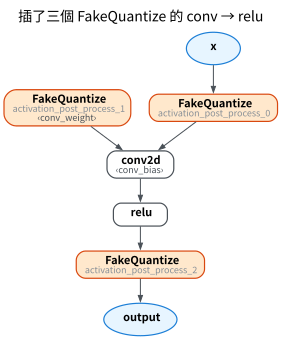

In [6]:
EPS = 2**-12  # 與 XNNPACKQuantizer 的 eps 相同


def fq_act():
    return FakeQuantize(observer=MinMaxObserver, dtype=torch.int8, qscheme=torch.per_tensor_affine,
                        quant_min=-128, quant_max=127, eps=EPS)


def fq_weight():
    return FakeQuantize(observer=PerChannelMinMaxObserver, ch_axis=0, dtype=torch.int8,
                        qscheme=torch.per_channel_symmetric, quant_min=-127, quant_max=127, eps=EPS)


fq_model = build_manual(copy.deepcopy(gm), fq_act, fq_weight)
draw(fq_model, title="插了三個 FakeQuantize 的 conv → relu")

同一筆輸入，分別餵 fp32 模型、observer 版（A 段的 `manual`）、fake quant 版：

In [7]:
x = torch.randn(4, 3, 16, 16)
with torch.no_grad():
    y_fp32, y_obs, y_fq = model(x), manual(x), fq_model(x)
obs_same, fq_same = torch.equal(y_obs, y_fp32), torch.equal(y_fq, y_fp32)
table([["observer 版", obs_same, "—"], ["FakeQuantize 版", fq_same, f"{sqnr(y_fp32, y_fq):.1f}"]],
      ["模型", "輸出 == fp32？", "對 fp32 的 SQNR (dB)"])

模型,輸出 == fp32？,對 fp32 的 SQNR (dB)
observer 版,True,—
FakeQuantize 版,False,40.2


In [8]:
assert obs_same and not fq_same

observer 版的輸出與 fp32 逐位元相同，fake quant 版則帶有量化誤差。

## C. `FakeQuantize` 的兩個開關

兩個開關是模組上的 buffer，用 `model.apply(disable_observer)` 這類函式對整張圖一次切換。
依序做三件事，看輸入 `x` 上那個 fake quant（`activation_post_process_0`）的 scale：

1. 兩個都開，餵一批範圍大很多的資料。
2. `disable_observer` 之後，再餵範圍更大的資料。
3. 再 `disable_fake_quant`，輸出是否回到 fp32。

In [9]:
fq_mod = fq_model.get_submodule("activation_post_process_0")
assert isinstance(fq_mod, FakeQuantize)


def state():
    flags = {name: getattr(fq_mod, f"{name}_enabled") for name in ("observer", "fake_quant")}  # 兩個開關是 buffer
    return " ".join(f"{name}={int(t[0])}" for name, t in flags.items() if isinstance(t, torch.Tensor))


big = torch.randn(4, 3, 16, 16) * 5
scales = [float(fq_mod.scale)]
with torch.no_grad():
    fq_model(big)
    scales.append(float(fq_mod.scale))
    rows = [[state(), "餵 5 倍幅度的資料", f"{scales[0]:.5f} → {scales[1]:.5f}"]]

    fq_model.apply(disable_observer)
    fq_model(big * 10)
    scales.append(float(fq_mod.scale))
    rows.append([state(), "再餵 50 倍幅度的資料", f"{scales[1]:.5f} → {scales[2]:.5f}"])

    fq_model.apply(disable_fake_quant)
    back_to_fp32 = torch.equal(fq_model(x), y_fp32)
    rows.append([state(), "輸出 == fp32？", str(back_to_fp32)])
table(rows, ["開關狀態", "做了什麼", "scale／結果"])

開關狀態,做了什麼,scale／結果
observer=1 fake_quant=1,餵 5 倍幅度的資料,0.02829 → 0.15217
observer=0 fake_quant=1,再餵 50 倍幅度的資料,0.15217 → 0.15217
observer=0 fake_quant=0,輸出 == fp32？,True


In [10]:
assert scales[1] > scales[0] and scales[2] == scales[1] and back_to_fp32
_ = fq_model.apply(enable_fake_quant)  # 恢復成兩個都開
_ = fq_model.apply(enable_observer)

- **observer 開著**：scale 跟著新資料變大。
- **`disable_observer`**：scale 凍結，再大的資料也不會改變它，但 quantize → dequantize 照做。
- **`disable_fake_quant`**：不做 quantize → dequantize，輸出回到 fp32。

QAT（M06）會在不同時間切換這兩個開關，例如評估前保留 fake quant 但關掉 observer（M06-2）。

## 小結

- `prepare_pt2e` 插 observer = `add_submodule` + `call_module` + `replace_all_uses_with`，手做的結果與它逐項相同。
- observer 的種類與參數來自 `QuantizationSpec` 的 `observer_or_fake_quant_ctr`。
- `FakeQuantize` = observer + quantize → dequantize；兩件事各有一個開關。
- 下一步：M02-3 把校準好的 observer 換成 quantize／dequantize node，也就是手做 `convert_pt2e`。